# 🚢 Lekcja 1: Witaj na pokładzie Titanica! Czym różni się Klasyfikacja od Regresji i co kryją nasze pliki?

Witaj w naszym kursie poświęconym najsłynniejszemu wyzwaniu w świecie Data Science — analizie katastrofy statku **RMS Titanic** z 15 kwietnia 1912 roku.

Zanim wczytamy dane, wyjaśnijmy sobie najważniejszą różnicę w całym Machine Learningu:

---

### 🎯 Klasyfikacja kontra Regresja — dwie główne gałęzie Machine Learningu

Wszystkie problemy, w których uczymy komputer na przykładach z odpowiedziami, dzielą się na dwa główne typy w zależności od tego, **o co pytamy model**:

| Cecha | 🏷️ KLASYFIKACJA (*Classification* — nasz kurs Titanica!) | 📈 REGRESJA (*Regression* — nasz kurs House Prices!) |
| :--- | :--- | :--- |
| **Jakie pytanie zadajemy?** | **„Która to kategoria? (TAK czy NIE / `1` czy `0`)”** | **„Ile dokładnie? (Podaj liczbę na skali)”** |
| **Co jest odpowiedzią modelu (`y`)?** | Konkretna etykieta / klasa, np.:<br>• **`1` (Przeżył)** lub **`0` (Zginął)**<br>• `Spam` lub `Nie-spam`<br>• `Chory` lub `Zdrowy` | Ciągła liczba rzeczywista, np.:<br>• Cena domu: **`185 500 $`**<br>• Temperatura jutro: **`21.4 °C`**<br>• Czas dojazdu: **`34 minuty`** |
| **Jak oceniamy model?** | **Procent trafnych decyzji (*Accuracy*)** — np. *„Model odgadł los 82% pasażerów!”* | **Średni błąd o ile się pomylił (*MAE / RMSE*)** — np. *„Model pomylił się średnio o 16 000 \$”*. |

---

### 📂 Po co są 3 pliki w folderze `../data/`?

1. 📄 **`train.csv` (Zbiór treningowy — „Księga historyczna z odpowiedziami”)**  
   Zawiera dane o **891 pasażerach**: ich płeć, wiek, klasę biletu, cenę biletu oraz najważniejszą kolumnę **`Survived`** (`1` = przeżył katastrofę, `0` = nie przeżył). Z tego pliku nasz model będzie się uczył.

2. 📝 **`test.csv` (Zbiór testowy — „Arkusz egzaminacyjny”)**  
   Zawiera dane o **418 innych pasażerach** Titanica. Mamy ich wiek, klasę biletu i płeć, ale **brakuje tu kolumny `Survived`**! Naszym zadaniem będzie odgadnięcie, kto z tej grupy 418 osób uratował się w szalupie.

3. 📬 **`gender_submission.csv` (Wzór formularza odpowiedzi)**  
   Pokazuje, jak musi wyglądać plik, który na końcu wyślemy na Kaggle: dokładnie 418 wierszy i 2 kolumny (`PassengerId` oraz `Survived` wypełnione zerami i jedynkami).

---

### 📖 Słownik wszystkich 12 kolumn w tabeli Titanica

W przeciwieństwie do cen domów (gdzie kolumn było aż 81), na Titanicu mamy tylko **12 przejrzystych kolumn**:
* **`PassengerId`** — unikalny numer porządkowy pasażera (od 1 do 891 w `train.csv`).
* **`Survived`** — **nasz cel (*Target*)**: `0` = Nie przeżył, `1` = Przeżył.
* **`Pclass`** — klasa biletu (status społeczny i pokład): `1` = Pierwsza klasa (najbogatsi, górne pokłady), `2` = Druga klasa, `3` = Trzecia klasa (emigranci, dolne pokłady).
* **`Name`** — pełne imię, nazwisko oraz tytuł (np. `Mr.`, `Mrs.`, `Miss.`, `Master.`).
* **`Sex`** — płeć (`'male'` = mężczyzna, `'female'` = kobieta).
* **`Age`** — wiek w latach (u niemowląt zapisany jako ułamek, np. `0.42` roku).
* **`SibSp`** — (*Siblings / Spouses*) liczba rodzeństwa oraz małżonków płynących razem z pasażerem.
* **`Parch`** — (*Parents / Children*) liczba rodziców oraz dzieci płynących razem z pasażerem.
* **`Ticket`** — numer biletu.
* **`Fare`** — cena zapłacona za bilet (w brytyjskich funtach z 1912 roku).
* **`Cabin`** — numer kabiny (np. `'C85'`, `'B28'`).
* **`Embarked`** — port, w którym pasażer wsiadł na statek: **`S`** = Southampton (Anglia), **`C`** = Cherbourg (Francja), **`Q`** = Queenstown (Irlandia).

In [1]:
import pandas as pd

# 1. Wczytujemy oba pliki z folderu ../data/
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

# 2. Sprawdzamy wymiary (liczba wierszy, liczba kolumn)
print('Wymiary zbioru treningowego (train):', train.shape)
print('Wymiary zbioru testowego (test):    ', test.shape)

# 3. Wyświetlamy pierwsze 5 wierszy tabeli train
train.head()

Wymiary zbioru treningowego (train): (891, 12)
Wymiary zbioru testowego (test):     (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 🔍 Rozbiórka kodu na czynniki pierwsze

* **`import pandas as pd`** — ładujemy bibliotekę `pandas` (nasz programowy odpowiednik Excela) i nadajemy jej krótki pseudonim `pd`.
* **`train = pd.read_csv('../data/train.csv')`** — sięgamy za pomocą kropki `.` do biblioteki `pd` po funkcję `read_csv()`. Nawiasy okrągłe `()` wykonują czynność wczytania pliku, a znak `=` zapisuje tabelę do zmiennej `train`.
* **`train.shape` vs `test.shape`**:
  * `train.shape` zwraca **`(891, 12)`** — 891 pasażerów i 12 kolumn.
  * `test.shape` zwraca **`(418, 11)`** — 418 pasażerów i **11 kolumn** (brakuje dokładnie jednej kolumny: odpowiedzi `Survived`!).
* **`train.head()`** — wyświetla pierwsze 5 wierszy tabeli. Zwróć uwagę na kolumnę `Cabin` w pierwszych wierszach: widać tam już pierwsze puste miejsca **`NaN`** (*Not a Number*), którymi zajmiemy się w Lekcji 3!

--- Podsumowanie kolumny Survived (0 = Zginął, 1 = Przeżył) ---
Survived
0    549
1    342
Name: count, dtype: int64

Odsetek osób, które przeżyły katastrofę: 38.4%

--- Statystyki wieku (Age) oraz ceny biletu (Fare) ---
          Age    Fare
count  714.00  891.00
mean    29.70   32.20
std     14.53   49.69
min      0.42    0.00
25%     20.12    7.91
50%     28.00   14.45
75%     38.00   31.00
max     80.00  512.33


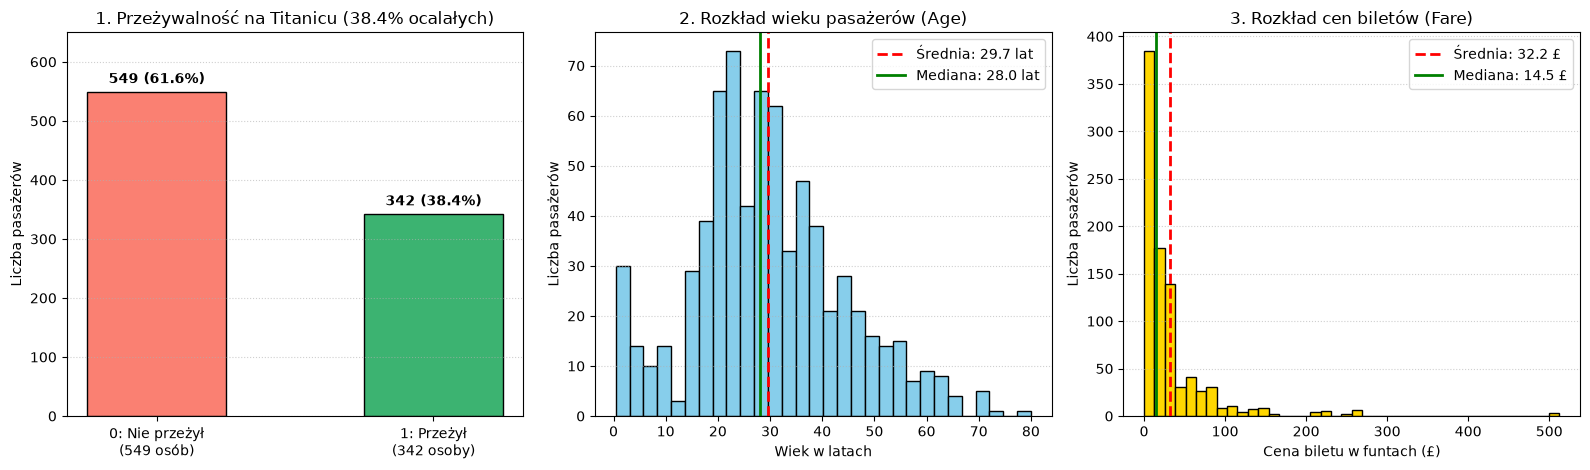

In [2]:
import matplotlib.pyplot as plt

# 1. Policzmy, ilu pasażerów zginęło (0), a ilu przeżyło (1)
liczba_ocalalych = train['Survived'].value_counts()
procent_ocalalych = train['Survived'].mean() * 100

print('--- Podsumowanie kolumny Survived (0 = Zginął, 1 = Przeżył) ---')
print(liczba_ocalalych)
print(f'\nOdsetek osób, które przeżyły katastrofę: {procent_ocalalych:.1f}%\n')

# 2. Podsumowanie statystyczne wieku (Age) oraz ceny biletu (Fare)
print('--- Statystyki wieku (Age) oraz ceny biletu (Fare) ---')
print(train[['Age', 'Fare']].describe().round(2))

# 3. WIZUALIZACJA: 3 wykresy obok siebie (Przeżywalność, Rozkład wieku, Rozkład cen biletów)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.8))

# Wykres 1: Ilu zginęło vs ilu przeżyło
etykiety = ['0: Nie przeżył\n(549 osób)', '1: Przeżył\n(342 osoby)']
ax1.bar(etykiety, liczba_ocalalych.values, color=['salmon', 'mediumseagreen'], edgecolor='black', width=0.5)
ax1.set_title(f'1. Przeżywalność na Titanicu ({procent_ocalalych:.1f}% ocalałych)')
ax1.set_ylabel('Liczba pasażerów')
ax1.set_ylim(0, 650)
for i, v in enumerate(liczba_ocalalych.values):
    ax1.text(i, v + 15, f'{v} ({v/len(train)*100:.1f}%)', ha='center', fontweight='bold')
ax1.grid(axis='y', linestyle=':', alpha=0.6)

# Wykres 2: Rozkład wieku pasażerów (Age)
ax2.hist(train['Age'].dropna(), bins=30, color='skyblue', edgecolor='black')
ax2.axvline(train['Age'].mean(), color='red', linestyle='--', linewidth=2, label=f"Średnia: {train['Age'].mean():.1f} lat")
ax2.axvline(train['Age'].median(), color='green', linestyle='-', linewidth=2, label=f"Mediana: {train['Age'].median():.1f} lat")
ax2.set_title('2. Rozkład wieku pasażerów (Age)')
ax2.set_xlabel('Wiek w latach')
ax2.set_ylabel('Liczba pasażerów')
ax2.legend()
ax2.grid(axis='y', linestyle=':', alpha=0.6)

# Wykres 3: Rozkład cen biletów (Fare)
ax3.hist(train['Fare'], bins=40, color='gold', edgecolor='black')
ax3.axvline(train['Fare'].mean(), color='red', linestyle='--', linewidth=2, label=f"Średnia: {train['Fare'].mean():.1f} £")
ax3.axvline(train['Fare'].median(), color='green', linestyle='-', linewidth=2, label=f"Mediana: {train['Fare'].median():.1f} £")
ax3.set_title('3. Rozkład cen biletów (Fare)')
ax3.set_xlabel('Cena biletu w funtach (£)')
ax3.set_ylabel('Liczba pasażerów')
ax3.legend()
ax3.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🧮 Matematyka pod maską: Dlaczego średnia z zer i jedynek (`.mean()`) daje od razu procent ocalałych?

#### 1. Trik z `.mean()` na kolumnie `0` / `1`
Zauważ, jak policzyliśmy procent ocalałych w kodzie powyżej: `train['Survived'].mean() * 100`.
Dlaczego zwykła średnia arytmetyczna (`.mean()`) z kolumny `Survived` daje od razu odsetek osób, które przeżyły?

Sprawdźmy to na wzorze średniej arytmetycznej:
$$\text{Średnia} = \frac{\text{Suma wszystkich wartości w kolumnie}}{\text{Liczba wszystkich pasażerów (891)}}$$

* Ponieważ w kolumnie `Survived` zmarli mają wartość **`0`**, a ocalali wartość **`1`**, to dodając do siebie wszystkie wiersze ($0 + 1 + 1 + 0 + \dots$), **zera nic nie dodają**, a jedynki po prostu **zliczają liczbę ocalałych (`342`)**!
* Dzieląc sumę (`342`) przez wszystkich pasażerów (`891`), dostajemy:
  $$\frac{342}{891} \approx 0.3838 \quad (\text{czyli po pomnożeniu przez } 100:\ \mathbf{38.4\%})$$

> 💡 **Zapamiętaj ten trik!** W całym kursie Titanica, ilekroć będziemy chcieli sprawdzić, jaki procent danej grupy przeżył (np. procent ocalałych kobiet albo pasażerów 1. klasy), wystarczy, że policzymy `.mean()` na kolumnie `'Survived'`!

---

#### 2. Co mówią nam wykresy wieku (`Age`) i ceny biletu (`Fare`)?
* **Metoda `.value_counts()`** — zlicza, ile razy wystąpiła każda kategoria w kolumnie (`549` zer oraz `342` jedynki).
* **Wykres 2 (`Age`):** Większość pasażerów to ludzie młodzi (między 20 a 35 rokiem życia). Średnia (`29.7` lat) i mediana (`28.0` lat) leżą bardzo blisko siebie. Zwróć jednak uwagę w `.describe()` na wiersz `count`: dla wieku wynosi on **`714`** (a nie `891`!). Oznacza to, że dla **177 pasażerów nie znamy wieku**.
* **Wykres 3 (`Fare`):** Tutaj widzimy dokładnie to samo zjawisko „miliardera w barze”, które widzieliśmy w cenach domów! Połowa pasażerów (mediana) płynęła z tanim biletem za **`14.45 £`** lub mniej, ale kilkunastu bogaczy z luksusowych apartamentów 1. klasy zapłaciło po **`250 – 512 £`**, ciągnąc średnią w górę do **`32.20 £`**.

In [3]:
# 🎯 ĆWICZENIE: Kim byli posiadacze najdroższych biletów na Titanicu (Fare > 200 £)?
#
# Przypomnienie z pandas: filtrowanie wierszy zapisujemy w nawiasach kwadratowych: tabela[warunek]
#
# 1. Stwórz zmienną `najdrozsze_bilety`, filtrując z tabeli `train` pasażerów, gdzie train['Fare'] > 200
# 2. Sprawdź, ilu było takich pasażerów, wypisując `najdrozsze_bilety.shape`
# 3. Oblicz, jaki ułamek (lub procent) z nich przeżył, wywołując: print(najdrozsze_bilety['Survived'].mean() * 100)
# 4. Wyświetl ich imiona, klasę, płeć, cenę biletu i czy przeżyli:
#    najdrozsze_bilety[['Name', 'Pclass', 'Sex', 'Fare', 'Survived']]

# Miejsce na Twój kod:


---
### 📌 Podsumowanie lekcji w 3 punktach

1. **Klasyfikacja kontra Regresja:** W projekcie Titanic rozwiązujemy problem **klasyfikacji binarnej** — nasz model nie przewiduje kwoty w dolarach, lecz jedną z dwóch kategorii: **`0` (Nie przeżył)** albo **`1` (Przeżył)** dla 418 pasażerów z pliku `../data/test.csv`.
2. **Matematyczny trik z `.mean()` na kolumnie `0`/`1`:** Średnia arytmetyczna z kolumny zawierającej wyłącznie zera i jedynki (`train['Survived'].mean()`) automatycznie daje ułamek jedynek — dzięki temu wiemy, że katastrofę przeżyło **342 z 891 pasażerów (`38.4%`)**.
3. **Rozkład cech pasażerów:** Wiek pasażerów (`Age`) koncentruje się wokół `28–30` lat (ale brakuje go u 177 osób), natomiast rozkład cen biletów (`Fare`) jest silnie prawostronnie skośny (mediana to `14.45 £`, a najdroższe bilety sięgają `512.33 £`).